# BCG X | PowerCo Customer Churn — Feature Engineering

**Objective:** Recreate Estelle's proposed December-versus-January off-peak price features, then engineer a few additional features and inspect how they relate to churn.

**Files required:** `clean_data_after_eda.csv` and `price_data.csv` in the same folder as this notebook.

**Important:** This notebook explores predictive signals, not causation. A feature showing different values for churned and retained customers does not prove that it caused churn. Before modeling, feature timing and leakage must be checked carefully.

## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

## 2. Load and inspect the supplied data

In [4]:
CLIENT_FILE = Path(r"C:\Users\riaka\OneDrive\Desktop\clean_data_after_eda.csv")
PRICE_FILE = Path(r"C:\Users\riaka\Downloads\price_data (1).csv")

if not CLIENT_FILE.exists():
    raise FileNotFoundError(f"Missing {CLIENT_FILE.resolve()}. Put it beside this notebook.")
if not PRICE_FILE.exists():
    raise FileNotFoundError(f"Missing {PRICE_FILE.resolve()}. Put it beside this notebook.")

df = pd.read_csv(CLIENT_FILE)
price_df = pd.read_csv(PRICE_FILE)

for col in ["date_activ", "date_end", "date_modif_prod", "date_renewal"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

price_df["price_date"] = pd.to_datetime(price_df["price_date"], errors="coerce")

print("Clean client data:", df.shape)
print("Historical price data:", price_df.shape)
display(df.head(3))
display(price_df.head(3))

Clean client data: (14606, 44)
Historical price data: (193002, 8)


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,var_year_price_off_peak_var,var_year_price_peak_var,var_year_price_mid_peak_var,var_year_price_off_peak_fix,var_year_price_peak_fix,var_year_price_mid_peak_fix,var_year_price_off_peak,var_year_price_peak,var_year_price_mid_peak,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0000,0,0.0000,1.7800,0.1145,0.0981,40.6067,t,0.0000,25.4400,25.4400,2,678.9900,3,lxidpiddsbxsbosboudacockeimpuepw,43.6480,0.0001,0.0000,0.0004,1.1028,49.5507,22.0225,1.1028,49.5507,22.0230,0.0001,0.0000,0.0009,2.0863,99.5305,44.2358,2.0864,99.5306,44.2367,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.9500,0,0.0000,16.2700,0.1457,0.0000,44.3114,f,0.0000,16.3800,16.3800,1,18.8900,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.8000,0.0000,0.0006,0.0000,0.0065,0.0000,0.0000,0.0065,0.0006,0.0000,0.0000,0.0012,0.0000,0.0095,0.0000,0.0000,0.0095,0.0012,0.0000,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.9600,0,0.0000,38.7200,0.1658,0.0879,44.3114,f,0.0000,28.6000,28.6000,1,6.6000,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.8560,0.0000,0.0000,0.0000,0.0077,0.0000,0.0000,0.0077,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0


,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.1514,0.0000,0.0000,44.2669,0.0000,0.0000
1,038af19179925da21a25619c5a24b745,2015-02-01,0.1514,0.0000,0.0000,44.2669,0.0000,0.0000
2,038af19179925da21a25619c5a24b745,2015-03-01,0.1514,0.0000,0.0000,44.2669,0.0000,0.0000


## 3. Recreate Estelle's price-difference features

The starter notebook compares the earliest recorded January price with the latest recorded December price for each customer. We sort the dates explicitly so that `.first()` and `.last()` reflect chronological order.

The features are:
- `offpeak_diff_dec_january_energy`: December off-peak variable price minus January off-peak variable price.
- `offpeak_diff_dec_january_power`: December off-peak fixed price minus January off-peak fixed price.

Note: the supplied price data's earliest/latest records should be checked to confirm they correspond to the intended January and December reference periods.

In [5]:
# Keep only rows with a usable ID and date, then sort chronologically.
price_df = price_df.dropna(subset=["id", "price_date"]).copy()
price_df = price_df.sort_values(["id", "price_date"])

monthly_price_by_id = (
    price_df.groupby(["id", "price_date"], as_index=False)
    .agg(
        price_off_peak_var=("price_off_peak_var", "mean"),
        price_off_peak_fix=("price_off_peak_fix", "mean")
    )
    .sort_values(["id", "price_date"])
)

first_prices = monthly_price_by_id.groupby("id", as_index=False).first()
last_prices = monthly_price_by_id.groupby("id", as_index=False).last()

first_prices = first_prices[["id", "price_date", "price_off_peak_var", "price_off_peak_fix"]].rename(
    columns={
        "price_date": "first_price_date",
        "price_off_peak_var": "first_offpeak_var",
        "price_off_peak_fix": "first_offpeak_fix"
    }
)
last_prices = last_prices[["id", "price_date", "price_off_peak_var", "price_off_peak_fix"]].rename(
    columns={
        "price_date": "last_price_date",
        "price_off_peak_var": "last_offpeak_var",
        "price_off_peak_fix": "last_offpeak_fix"
    }
)

diff = first_prices.merge(last_prices, on="id", how="inner", validate="one_to_one")
diff["offpeak_diff_dec_january_energy"] = diff["last_offpeak_var"] - diff["first_offpeak_var"]
diff["offpeak_diff_dec_january_power"] = diff["last_offpeak_fix"] - diff["first_offpeak_fix"]

display(diff[[
    "id", "first_price_date", "last_price_date",
    "offpeak_diff_dec_january_energy", "offpeak_diff_dec_january_power"
]].head())

print("Customers with price features:", diff["id"].nunique())
print("Price dates observed:", price_df["price_date"].min(), "to", price_df["price_date"].max())

,id,first_price_date,last_price_date,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,0002203ffbb812588b632b9e628cc38d,2015-01-01,2015-12-01,-0.0062,0.1629
1,0004351ebdd665e6ee664792efc4fd13,2015-01-01,2015-12-01,-0.0041,0.1778
2,0010bcc39e42b3c2131ed2ce55246e3c,2015-01-01,2015-12-01,0.0504,1.5000
3,0010ee3855fdea87602a5b7aba8e42de,2015-01-01,2015-12-01,-0.0100,0.1629
4,00114d74e963e47177db89bc70108537,2015-01-01,2015-12-01,-0.0040,-0.0000


Customers with price features: 16096
Price dates observed: 2015-01-01 00:00:00 to 2015-12-01 00:00:00


## 4. Merge engineered price features into the client dataset

We use a left join to preserve every customer row in the cleaned client data. `validate="one_to_one"` checks that the feature table has at most one row per customer.

In [6]:
df_fe = df.merge(
    diff[["id", "offpeak_diff_dec_january_energy", "offpeak_diff_dec_january_power"]],
    on="id",
    how="left",
    validate="one_to_one"
)

print("Before merge:", df.shape)
print("After merge:", df_fe.shape)
print("Missing energy price differences:", df_fe["offpeak_diff_dec_january_energy"].isna().sum())
print("Missing power price differences:", df_fe["offpeak_diff_dec_january_power"].isna().sum())

Before merge: (14606, 44)
After merge: (14606, 46)
Missing energy price differences: 0
Missing power price differences: 0


## 5. Create additional features

These examples use existing customer information and the precomputed price-variation fields in `clean_data_after_eda.csv`. They are candidate features; evaluate them before using them in a model.

In [7]:
# A. Relative/absolute price-change indicators
df_fe["abs_offpeak_energy_price_diff"] = df_fe["offpeak_diff_dec_january_energy"].abs()
df_fe["abs_offpeak_power_price_diff"] = df_fe["offpeak_diff_dec_january_power"].abs()

# B. Contract/customer tenure is already represented by num_years_antig.
# Add a simple grouped tenure feature for descriptive analysis.
if "num_years_antig" in df_fe.columns:
    df_fe["tenure_group"] = pd.cut(
        df_fe["num_years_antig"],
        bins=[-np.inf, 1, 3, 5, 10, np.inf],
        labels=["0–1 years", "1–3 years", "3–5 years", "5–10 years", "10+ years"],
        right=True
    )

# C. Combine available yearly price variation columns into a simple overall indicator.
yearly_variation_cols = [
    c for c in [
        "var_year_price_off_peak", "var_year_price_peak", "var_year_price_mid_peak"
    ] if c in df_fe.columns
]
if yearly_variation_cols:
    df_fe["mean_yearly_price_variation"] = df_fe[yearly_variation_cols].mean(axis=1)

# D. Combine available six-month price variation columns into a simple overall indicator.
six_month_variation_cols = [
    c for c in [
        "var_6m_price_off_peak", "var_6m_price_peak", "var_6m_price_mid_peak"
    ] if c in df_fe.columns
]
if six_month_variation_cols:
    df_fe["mean_6m_price_variation"] = df_fe[six_month_variation_cols].mean(axis=1)

new_features = [
    c for c in [
        "offpeak_diff_dec_january_energy",
        "offpeak_diff_dec_january_power",
        "abs_offpeak_energy_price_diff",
        "abs_offpeak_power_price_diff",
        "tenure_group",
        "mean_yearly_price_variation",
        "mean_6m_price_variation"
    ] if c in df_fe.columns
]
display(df_fe[["id", "churn"] + new_features].head())

,id,churn,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power,abs_offpeak_energy_price_diff,abs_offpeak_power_price_diff,tenure_group,mean_yearly_price_variation,mean_6m_price_variation
0,24011ae4ebbe3035111d65fa7c15bc57,1,0.0201,3.7010,0.0201,3.7010,1–3 years,24.2255,48.6179
1,d29c2c54acc38ff3c0614d0a653813dd,0,-0.0038,0.1778,0.0038,0.1778,5–10 years,0.0024,0.0036
2,764c75f661154dac3a6c254cd082ea7d,0,-0.0047,0.1778,0.0047,0.1778,5–10 years,0.0026,0.0000
3,bba03439a292a1e166f80264c16191cb,0,-0.0045,0.1778,0.0045,0.1778,5–10 years,0.0022,0.0000
4,149d57cf92fc41cf94415803a877cb4b,0,-0.0062,0.1629,0.0062,0.1629,5–10 years,0.0028,0.0000


## 6. Compare candidate features by churn group

We compare averages and medians for engineered numeric features. Differences are exploratory associations only; they do not establish causality or guarantee improved model performance.

churn                                            0          1
offpeak_diff_dec_january_energy count  13,187.0000 1,419.0000
                                mean       -0.0046    -0.0046
                                median     -0.0053    -0.0062
offpeak_diff_dec_january_power  count  13,187.0000 1,419.0000
                                mean        0.2773     0.2895
                                median      0.1629     0.1629
abs_offpeak_energy_price_diff   count  13,187.0000 1,419.0000
                                mean        0.0075     0.0085
                                median      0.0056     0.0066
abs_offpeak_power_price_diff    count  13,187.0000 1,419.0000
                                mean        0.3420     0.4027
                                median      0.1629     0.1629
mean_yearly_price_variation     count  13,187.0000 1,419.0000
                                mean        1.1837     1.6935
                                median      0.0026     0.0026
mean_6m_price_variation         count  13,187.0000 1,419.0000
                                mean        0.9583     1.4477
                                median      0.0000     0.0000

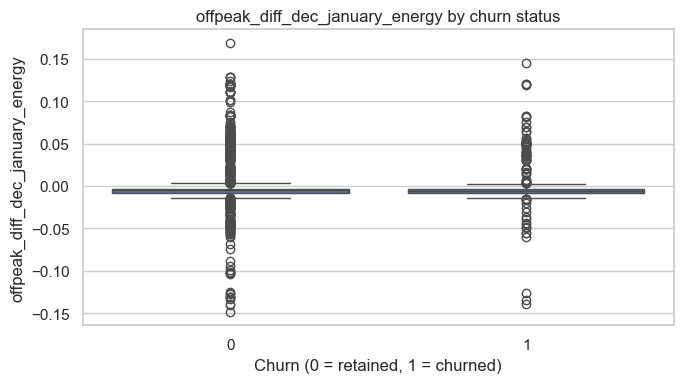

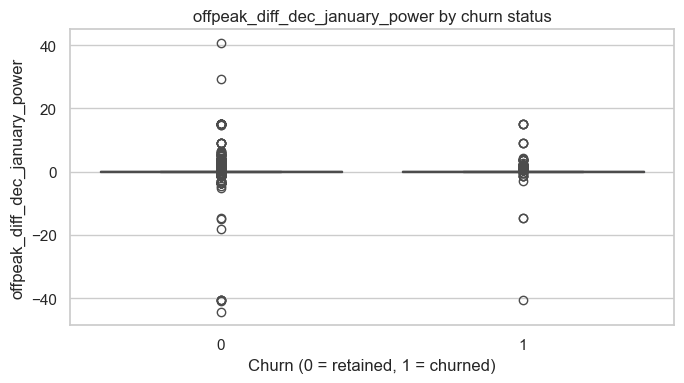

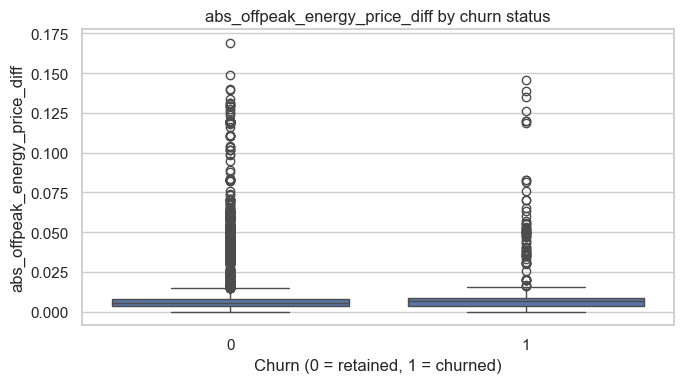

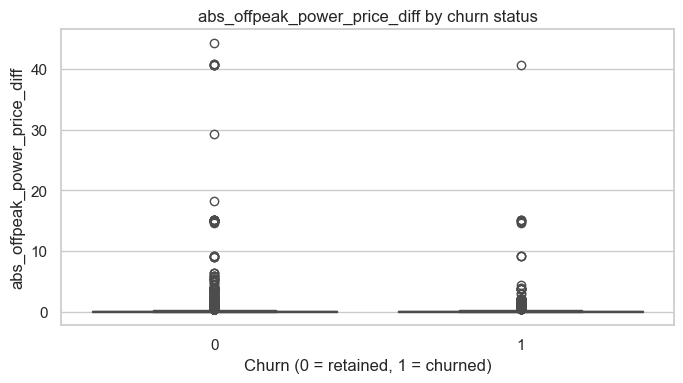

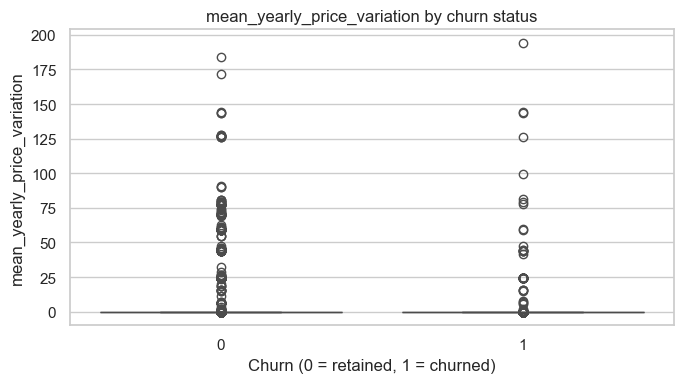

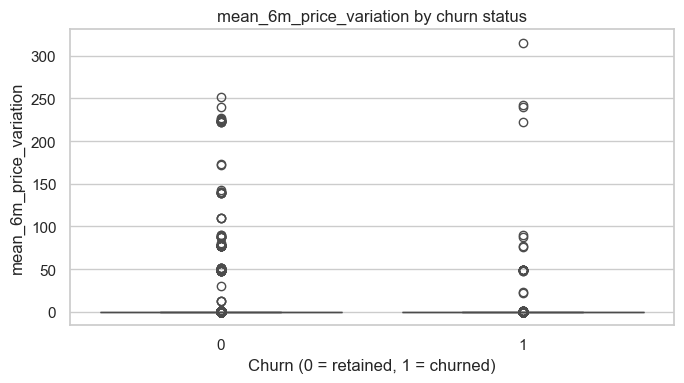

In [8]:
engineered_numeric = [
    c for c in [
        "offpeak_diff_dec_january_energy",
        "offpeak_diff_dec_january_power",
        "abs_offpeak_energy_price_diff",
        "abs_offpeak_power_price_diff",
        "mean_yearly_price_variation",
        "mean_6m_price_variation"
    ] if c in df_fe.columns
]

display(df_fe.groupby("churn")[engineered_numeric].agg(["count", "mean", "median"]).T)

for col in engineered_numeric:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_fe, x="churn", y=col)
    plt.title(f"{col} by churn status")
    plt.xlabel("Churn (0 = retained, 1 = churned)")
    plt.tight_layout()
    plt.show()

## 7. Churn rate by tenure group

This is a simple example of how an engineered categorical feature can support business interpretation.

,tenure_group,customers,churn_rate,churn_rate_pct
0,0–1 years,1,0.0000,0.0000
1,1–3 years,2444,0.1358,13.5800
2,3–5 years,6299,0.1067,10.6700
3,5–10 years,5554,0.0704,7.0400
4,10+ years,308,0.0779,7.7900


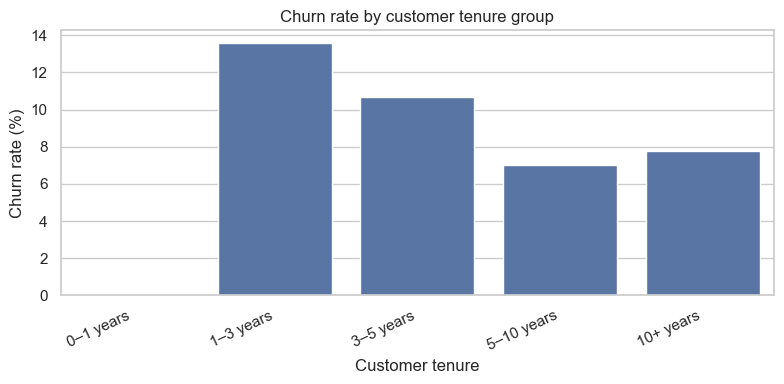

In [9]:
if "tenure_group" in df_fe.columns:
    tenure_churn = (
        df_fe.groupby("tenure_group", observed=False)
        .agg(customers=("churn", "size"), churn_rate=("churn", "mean"))
        .assign(churn_rate_pct=lambda x: (100 * x["churn_rate"]).round(2))
        .reset_index()
    )
    display(tenure_churn)

    plt.figure(figsize=(8, 4))
    sns.barplot(data=tenure_churn, x="tenure_group", y="churn_rate_pct")
    plt.title("Churn rate by customer tenure group")
    plt.xlabel("Customer tenure")
    plt.ylabel("Churn rate (%)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 8. Quality checks and save the engineered dataset

We verify that the merge has not changed the number of customer rows and inspect missing values in the new features. Save the result for the next stage if needed.

In [10]:
assert len(df_fe) == len(df), "Unexpected row-count change after feature merge."
assert df_fe["id"].is_unique, "Expected one row per customer in the client-level dataset."

display(df_fe[new_features].isna().sum().to_frame("missing_values"))
print("Final feature-engineered data shape:", df_fe.shape)

OUTPUT_FILE = Path("powerco_feature_engineered.csv")
df_fe.to_csv(OUTPUT_FILE, index=False)
print(f"Saved: {OUTPUT_FILE.resolve()}")

,missing_values
offpeak_diff_dec_january_energy,0
offpeak_diff_dec_january_power,0
abs_offpeak_energy_price_diff,0
abs_offpeak_power_price_diff,0
tenure_group,0
mean_yearly_price_variation,0
mean_6m_price_variation,0


Final feature-engineered data shape: (14606, 51)
Saved: C:\Users\riaka\Downloads\powerco_feature_engineered.csv


## 9. Interpretation and limitations

After running the notebook, summarize:
1. What is the range of the engineered off-peak price differences?
2. Do the distributions differ between churned and retained customers?
3. Does churn vary across tenure groups?
4. Which features look promising enough to test in a model?
5. What are the limitations?

**Critical limitation:** The starter approach uses each customer's first and last available price records, which may not literally be the preceding January and December for every customer. For a rigorous model, select the exact reference months and ensure all features are available before the churn prediction window. Avoid data leakage and validate feature usefulness using cross-validation.